HEART DISEASE DATASET

Dataset Shape:
(1025, 14)

First 5 Rows:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  

DATASET INFORMATION

Data Types and Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2  

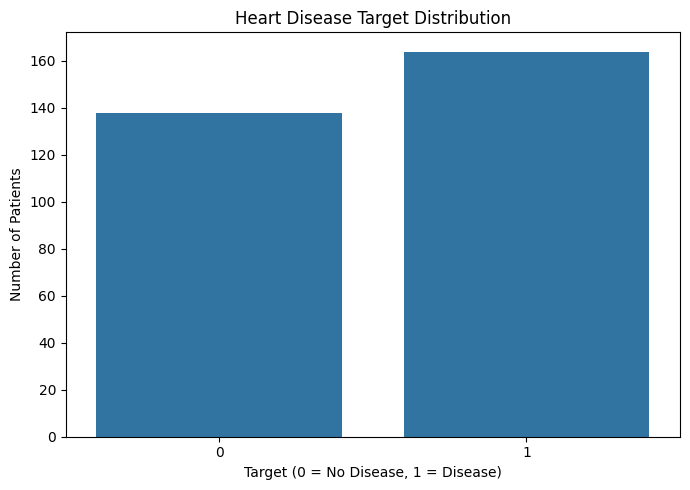

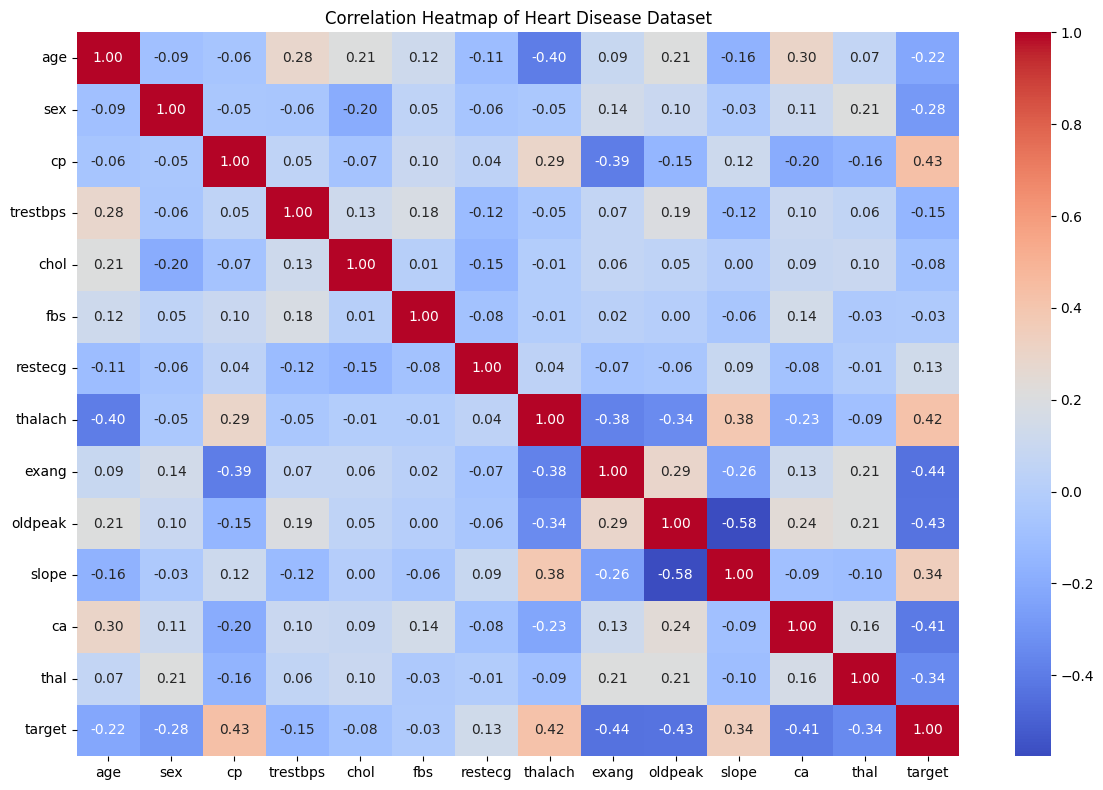

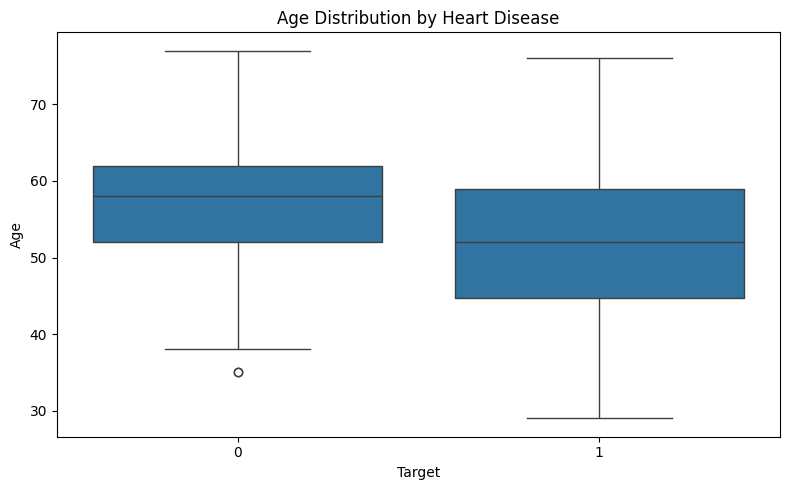

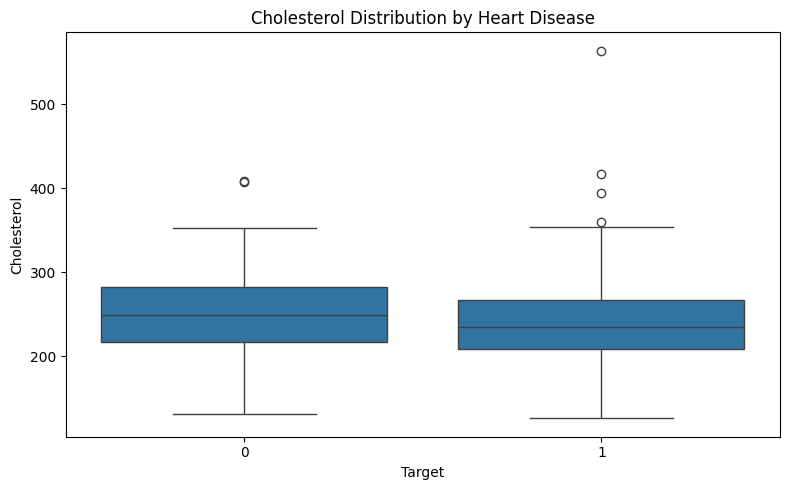

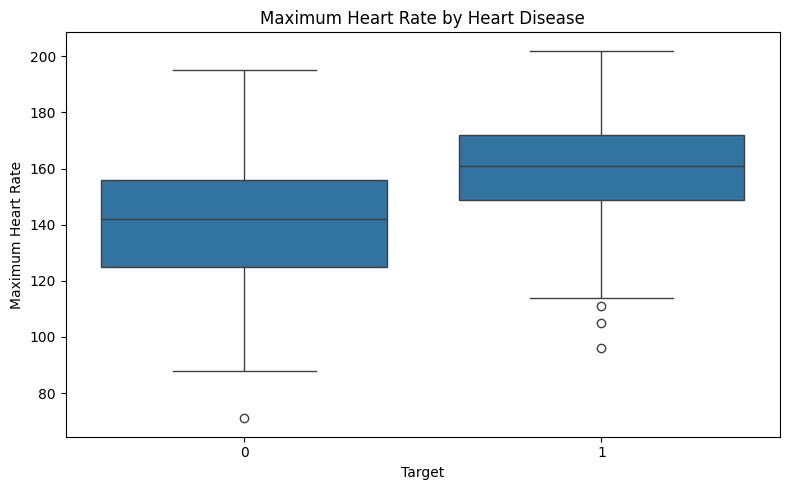


FEATURES AND TARGET
Features shape: (302, 13)
Target shape: (302,)

Feature columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

TRAIN / TEST SPLIT
Training samples: 241
Testing samples: 61

Training target distribution:
target
1    131
0    110
Name: count, dtype: int64

Testing target distribution:
target
1    33
0    28
Name: count, dtype: int64

MODEL TRAINING AND EVALUATION

Training: Logistic Regression
Accuracy : 80.33 %
Precision: 80.0 %
Recall   : 84.85 %
F1 Score : 82.35 %
ROC-AUC  : 0.8712

Training: K-Nearest Neighbors
Accuracy : 78.69 %
Precision: 77.78 %
Recall   : 84.85 %
F1 Score : 81.16 %
ROC-AUC  : 0.8377

Training: Decision Tree
Accuracy : 78.69 %
Precision: 81.25 %
Recall   : 78.79 %
F1 Score : 80.0 %
ROC-AUC  : 0.8268

Training: Support Vector Machine
Accuracy : 77.05 %
Precision: 77.14 %
Recall   : 81.82 %
F1 Score : 79.41 %
ROC-AUC  : 0.842

Training: Random Forest
Accuracy : 77.05 %
Precision

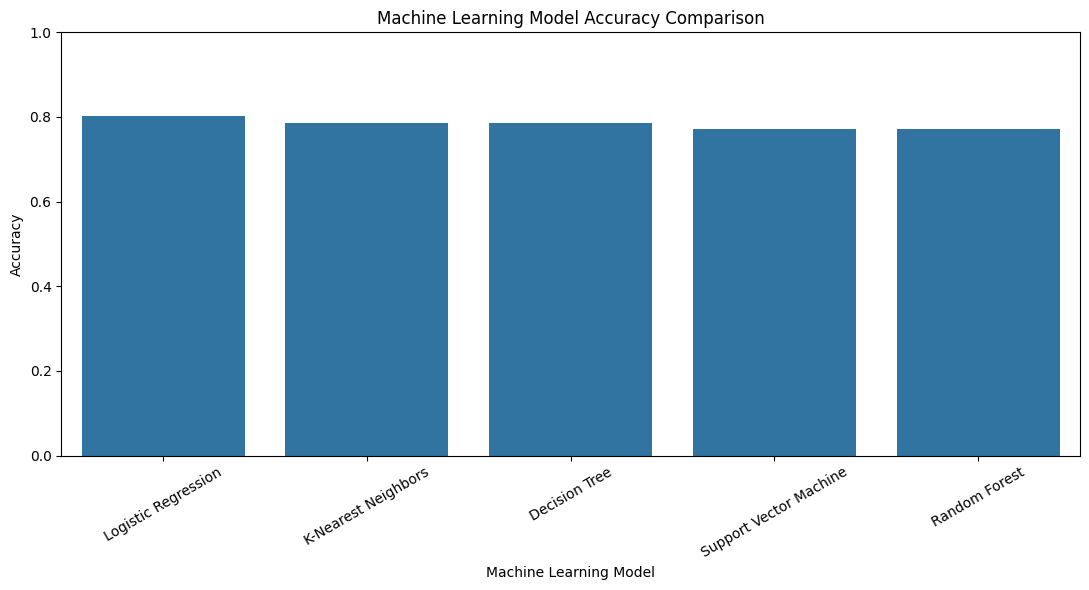

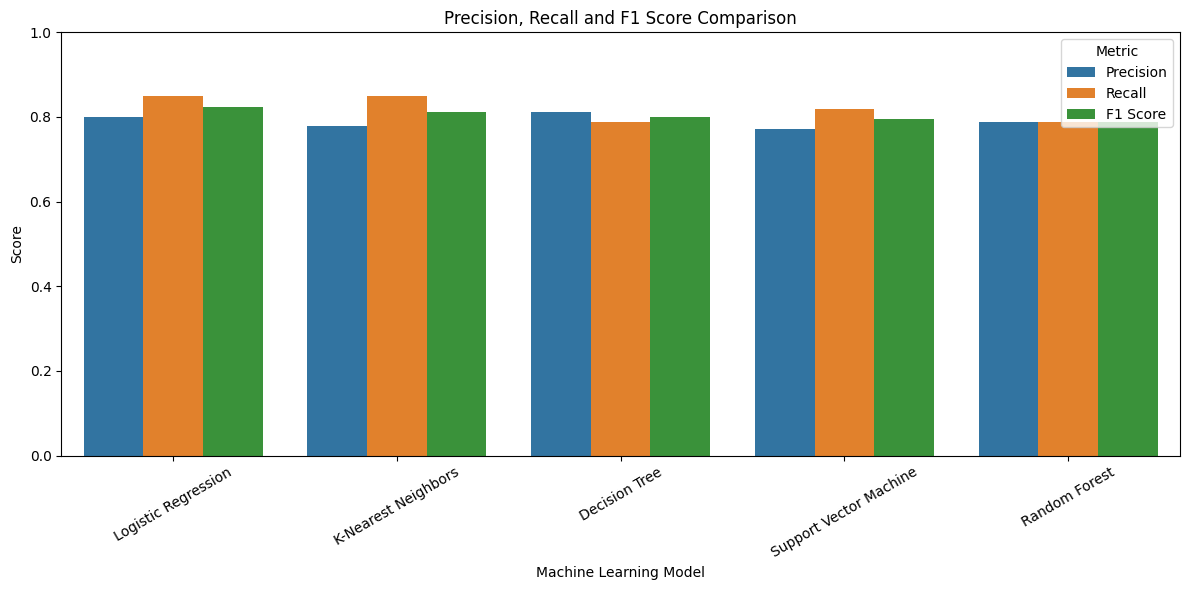

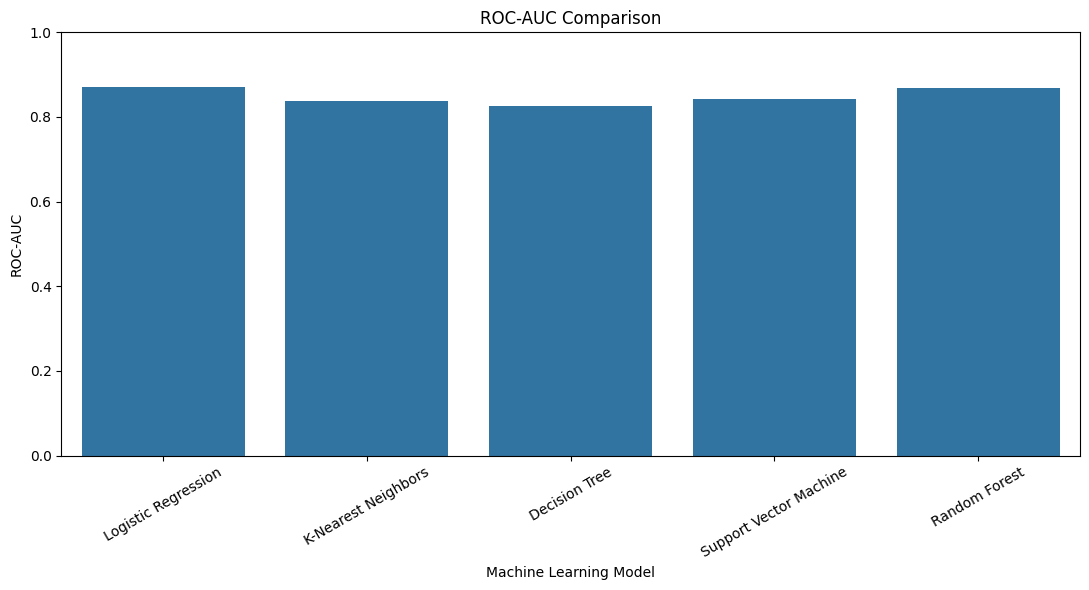


BEST MODEL
Best Model: Logistic Regression
Accuracy: 80.33 %
Precision: 80.0 %
Recall: 84.85 %
F1 Score: 82.35 %
ROC-AUC: 0.8712

CONFUSION MATRIX
[[21  7]
 [ 5 28]]


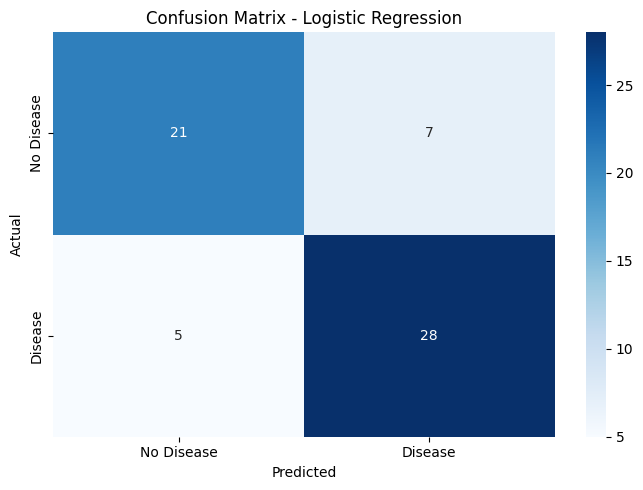


CLASSIFICATION REPORT
                  precision    recall  f1-score   support

No Heart Disease       0.81      0.75      0.78        28
   Heart Disease       0.80      0.85      0.82        33

        accuracy                           0.80        61
       macro avg       0.80      0.80      0.80        61
    weighted avg       0.80      0.80      0.80        61



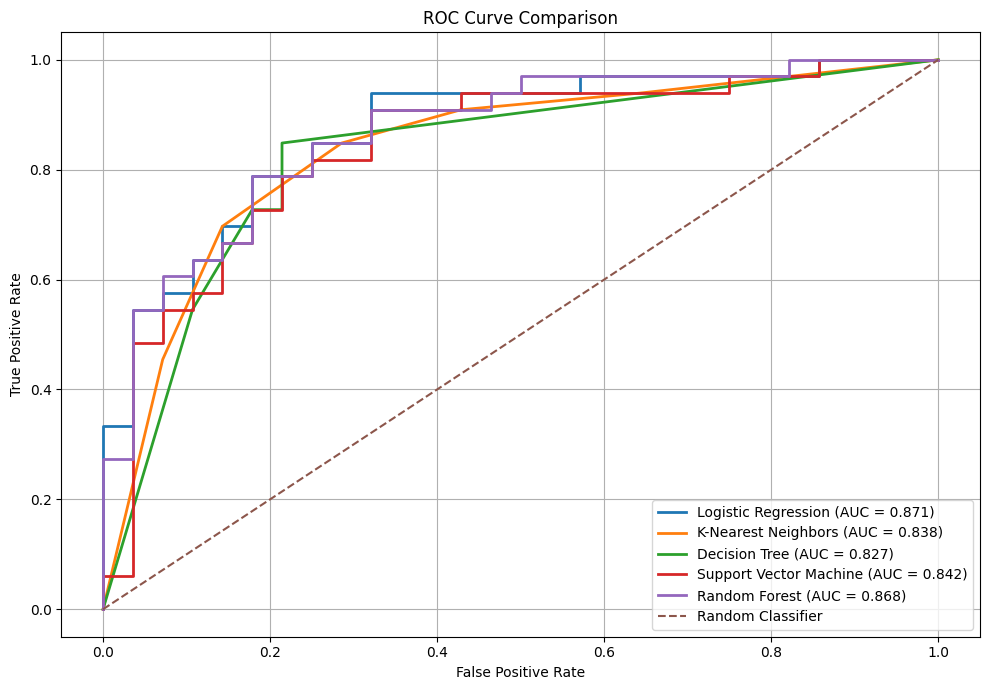


5-FOLD STRATIFIED CROSS-VALIDATION
Logistic Regression: 83.12% (± 2.81%)
K-Nearest Neighbors: 80.81% (± 2.74%)
Decision Tree: 78.46% (± 3.59%)
Support Vector Machine: 82.79% (± 2.61%)
Random Forest: 82.13% (± 3.32%)

Cross-Validation Results:
                 Model  Mean CV Accuracy  Std CV Accuracy
   Logistic Regression            0.8312           0.0281
Support Vector Machine            0.8279           0.0261
         Random Forest            0.8213           0.0332
   K-Nearest Neighbors            0.8081           0.0274
         Decision Tree            0.7846           0.0359


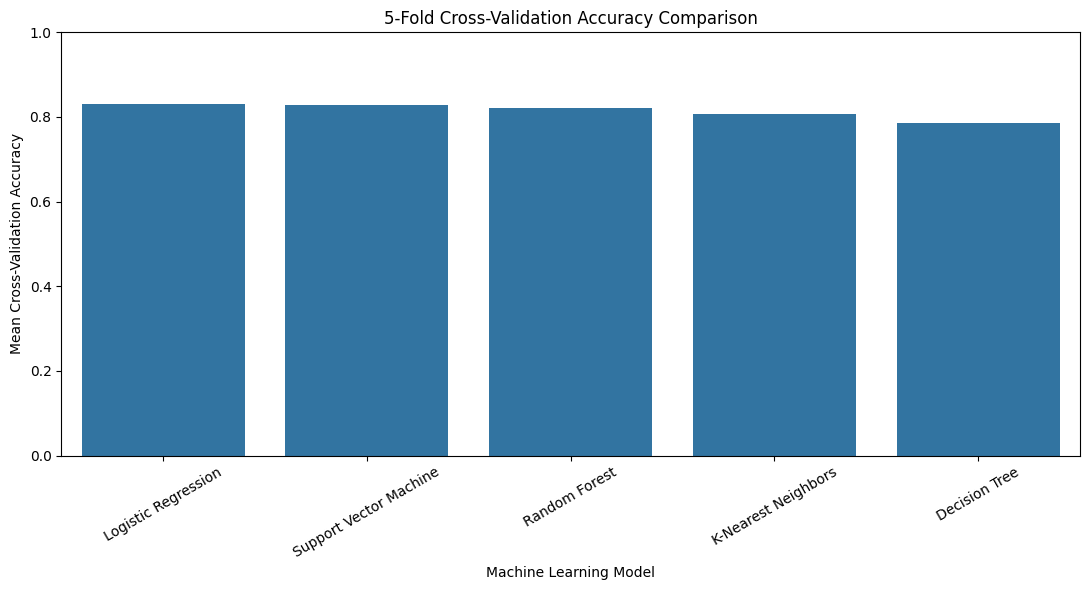


FINAL PROJECT SUMMARY

Dataset:
Original records: 1025
After duplicate removal: 302
Duplicate records removed: 723

Best Test Model: Logistic Regression
Test Accuracy: 80.33%
Precision: 80.00%
Recall: 84.85%
F1 Score: 82.35%
ROC-AUC: 0.8712

Best model based on F1 Score: Logistic Regression

SAMPLE PATIENT PREDICTION

Patient Features:
 age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  ca  thal
  61    0   0       145   307    0        0      146      1      1.0      1   0     3

Prediction:
No Heart Disease

Probability of No Heart Disease: 81.46 %
Probability of Heart Disease: 18.54 %

PREDICTION RESULTS
     age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
25    61    0   0       145   307    0        0      146      1      1.0   
65    59    1   3       170   288    0        0      159      0      0.2   
437   67    1   0       120   229    0        0      129      1      2.6   
58    67    1   2       152   212    0        0      15

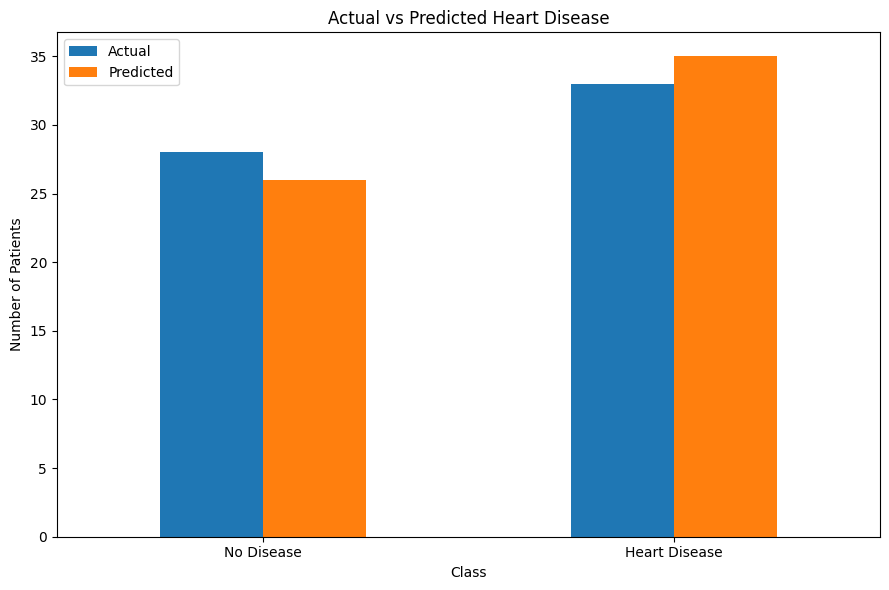


PROJECT COMPLETED SUCCESSFULLY

The project includes:

1. Data cleaning
2. Duplicate removal
3. Missing value checking
4. Exploratory Data Analysis
5. Correlation analysis
6. Stratified train/test split
7. Data scaling without leakage
8. Logistic Regression
9. KNN
10. Decision Tree
11. SVM
12. Random Forest
13. Accuracy comparison
14. Precision comparison
15. Recall comparison
16. F1-score comparison
17. ROC-AUC comparison
18. Confusion Matrix
19. Classification Report
20. ROC Curve
21. 5-Fold Cross-Validation
22. Best model selection
23. Heart disease prediction
24. Actual vs Predicted visualization

IMPORTANT:
Do not manually change the accuracy values.
Use the values generated by this notebook as your final results.



In [1]:
# ============================================================
# HEART DISEASE PREDICTION - COMPLETE MACHINE LEARNING PROJECT
# ============================================================

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")


# ============================================================
# 2. LOAD DATASET
# ============================================================

df = pd.read_csv("heart.csv")

print("=" * 60)
print("HEART DISEASE DATASET")
print("=" * 60)

print("\nDataset Shape:")
print(df.shape)

print("\nFirst 5 Rows:")
print(df.head())


# ============================================================
# 3. BASIC DATA INFORMATION
# ============================================================

print("\n" + "=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

print("\nData Types and Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
print(df.describe())


# ============================================================
# 4. REMOVE DUPLICATE RECORDS
# ============================================================

print("\n" + "=" * 60)
print("DUPLICATE REMOVAL")
print("=" * 60)

duplicate_count = df.duplicated().sum()

print("Duplicate rows before removal:", duplicate_count)

df_cleaned = df.drop_duplicates().copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_cleaned.shape)
print("Duplicate rows after removal:", df_cleaned.duplicated().sum())


# ============================================================
# 5. CHECK MISSING VALUES AFTER CLEANING
# ============================================================

print("\nMissing values after cleaning:")

print(df_cleaned.isnull().sum())


# ============================================================
# 6. TARGET DISTRIBUTION
# ============================================================

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_cleaned,
    x="target"
)

plt.title("Heart Disease Target Distribution")
plt.xlabel("Target (0 = No Disease, 1 = Disease)")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()


# ============================================================
# 7. CORRELATION HEATMAP
# ============================================================

plt.figure(figsize=(12, 8))

sns.heatmap(
    df_cleaned.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Heart Disease Dataset")

plt.tight_layout()
plt.show()


# ============================================================
# 8. AGE DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_cleaned,
    x="target",
    y="age"
)

plt.title("Age Distribution by Heart Disease")
plt.xlabel("Target")
plt.ylabel("Age")

plt.tight_layout()
plt.show()


# ============================================================
# 9. CHOLESTEROL DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_cleaned,
    x="target",
    y="chol"
)

plt.title("Cholesterol Distribution by Heart Disease")
plt.xlabel("Target")
plt.ylabel("Cholesterol")

plt.tight_layout()
plt.show()


# ============================================================
# 10. MAXIMUM HEART RATE DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_cleaned,
    x="target",
    y="thalach"
)

plt.title("Maximum Heart Rate by Heart Disease")
plt.xlabel("Target")
plt.ylabel("Maximum Heart Rate")

plt.tight_layout()
plt.show()


# ============================================================
# 11. FEATURES AND TARGET
# ============================================================

X = df_cleaned.drop("target", axis=1)
y = df_cleaned["target"]

print("\n" + "=" * 60)
print("FEATURES AND TARGET")
print("=" * 60)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())


# ============================================================
# 12. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\n" + "=" * 60)
print("TRAIN / TEST SPLIT")
print("=" * 60)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


# ============================================================
# 13. CREATE MACHINE LEARNING MODELS
# ============================================================

models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000
        ))
    ]),

    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Decision Tree": Pipeline([
        ("model", DecisionTreeClassifier(
            random_state=42,
            max_depth=5,
            min_samples_split=5,
            min_samples_leaf=2
        ))
    ]),

    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            probability=True,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("model", RandomForestClassifier(
            n_estimators=200,
            max_depth=6,
            min_samples_split=5,
            min_samples_leaf=2,
            random_state=42
        ))
    ])
}


# ============================================================
# 14. TRAIN AND EVALUATE ALL MODELS
# ============================================================

results = []
trained_models = {}

print("\n" + "=" * 60)
print("MODEL TRAINING AND EVALUATION")
print("=" * 60)

for model_name, model in models.items():

    print("\nTraining:", model_name)

    # Train
    model.fit(X_train, y_train)

    # Prediction
    y_pred = model.predict(X_test)

    # Probability
    if hasattr(model, "predict_proba"):
        y_probability = model.predict_proba(X_test)[:, 1]
    else:
        y_probability = model.decision_function(X_test)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test,
        y_probability
    )

    # Store results
    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    })

    trained_models[model_name] = model

    print("Accuracy :", round(accuracy * 100, 2), "%")
    print("Precision:", round(precision * 100, 2), "%")
    print("Recall   :", round(recall * 100, 2), "%")
    print("F1 Score :", round(f1 * 100, 2), "%")
    print("ROC-AUC  :", round(roc_auc, 4))


# ============================================================
# 15. MODEL COMPARISON TABLE
# ============================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 60)
print("MODEL COMPARISON")
print("=" * 60)

print(
    results_df.round(4).to_string(index=False)
)


# ============================================================
# 16. ACCURACY COMPARISON
# ============================================================

plt.figure(figsize=(11, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")

plt.xticks(rotation=30)

plt.ylim(0, 1)

plt.tight_layout()
plt.show()


# ============================================================
# 17. PRECISION, RECALL AND F1 COMPARISON
# ============================================================

metrics_df = results_df.melt(
    id_vars="Model",
    value_vars=[
        "Precision",
        "Recall",
        "F1 Score"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=metrics_df,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 Score Comparison")

plt.xlabel("Machine Learning Model")
plt.ylabel("Score")

plt.xticks(rotation=30)

plt.ylim(0, 1)

plt.tight_layout()
plt.show()


# ============================================================
# 18. ROC-AUC COMPARISON
# ============================================================

plt.figure(figsize=(11, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="ROC-AUC"
)

plt.title("ROC-AUC Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("ROC-AUC")

plt.xticks(rotation=30)

plt.ylim(0, 1)

plt.tight_layout()
plt.show()


# ============================================================
# 19. SELECT BEST MODEL
# ============================================================

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

best_row = results_df.iloc[0]

print("\n" + "=" * 60)
print("BEST MODEL")
print("=" * 60)

print("Best Model:", best_model_name)

print(
    "Accuracy:",
    round(best_row["Accuracy"] * 100, 2),
    "%"
)

print(
    "Precision:",
    round(best_row["Precision"] * 100, 2),
    "%"
)

print(
    "Recall:",
    round(best_row["Recall"] * 100, 2),
    "%"
)

print(
    "F1 Score:",
    round(best_row["F1 Score"] * 100, 2),
    "%"
)

print(
    "ROC-AUC:",
    round(best_row["ROC-AUC"], 4)
)


# ============================================================
# 20. BEST MODEL PREDICTIONS
# ============================================================

y_pred_best = best_model.predict(X_test)

if hasattr(best_model, "predict_proba"):
    y_prob_best = best_model.predict_proba(X_test)[:, 1]
else:
    y_prob_best = best_model.decision_function(X_test)


# ============================================================
# 21. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred_best
)

print("\n" + "=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

print(cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Disease",
        "Disease"
    ],
    yticklabels=[
        "No Disease",
        "Disease"
    ]
)

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()


# ============================================================
# 22. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_best,
        target_names=[
            "No Heart Disease",
            "Heart Disease"
        ],
        zero_division=0
    )
)


# ============================================================
# 23. ROC CURVE FOR ALL MODELS
# ============================================================

plt.figure(figsize=(10, 7))

for model_name, model in trained_models.items():

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = model.decision_function(X_test)

    fpr, tpr, _ = roc_curve(
        y_test,
        y_prob
    )

    auc_score = roc_auc_score(
        y_test,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {auc_score:.3f})"
    )


# Random classifier line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()

plt.grid()

plt.tight_layout()
plt.show()


# ============================================================
# 24. 5-FOLD STRATIFIED CROSS-VALIDATION
# ============================================================

print("\n" + "=" * 60)
print("5-FOLD STRATIFIED CROSS-VALIDATION")
print("=" * 60)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for model_name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    cv_results.append({
        "Model": model_name,
        "Mean CV Accuracy": scores.mean(),
        "Std CV Accuracy": scores.std()
    })

    print(
        f"{model_name}: "
        f"{scores.mean() * 100:.2f}% "
        f"(± {scores.std() * 100:.2f}%)"
    )


# ============================================================
# 25. CROSS-VALIDATION TABLE
# ============================================================

cv_df = pd.DataFrame(cv_results)

cv_df = cv_df.sort_values(
    by="Mean CV Accuracy",
    ascending=False
).reset_index(drop=True)

print("\nCross-Validation Results:")

print(
    cv_df.round(4).to_string(index=False)
)


# ============================================================
# 26. CROSS-VALIDATION VISUALIZATION
# ============================================================

plt.figure(figsize=(11, 6))

sns.barplot(
    data=cv_df,
    x="Model",
    y="Mean CV Accuracy"
)

plt.title(
    "5-Fold Cross-Validation Accuracy Comparison"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Mean Cross-Validation Accuracy")

plt.xticks(rotation=30)

plt.ylim(0, 1)

plt.tight_layout()
plt.show()


# ============================================================
# 27. FINAL MODEL PERFORMANCE SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("FINAL PROJECT SUMMARY")
print("=" * 60)

print("\nDataset:")
print("Original records:", len(df))
print("After duplicate removal:", len(df_cleaned))
print("Duplicate records removed:", len(df) - len(df_cleaned))

print("\nBest Test Model:", best_model_name)

print(
    "Test Accuracy:",
    f"{best_row['Accuracy'] * 100:.2f}%"
)

print(
    "Precision:",
    f"{best_row['Precision'] * 100:.2f}%"
)

print(
    "Recall:",
    f"{best_row['Recall'] * 100:.2f}%"
)

print(
    "F1 Score:",
    f"{best_row['F1 Score'] * 100:.2f}%"
)

print(
    "ROC-AUC:",
    f"{best_row['ROC-AUC']:.4f}"
)

print("\nBest model based on F1 Score:", best_model_name)


# ============================================================
# 28. SAMPLE PATIENT PREDICTION
# ============================================================

print("\n" + "=" * 60)
print("SAMPLE PATIENT PREDICTION")
print("=" * 60)

# Select one patient from test data
sample_patient = X_test.iloc[[0]]

sample_prediction = best_model.predict(
    sample_patient
)[0]

sample_probability = best_model.predict_proba(
    sample_patient
)[0]

print("\nPatient Features:")
print(sample_patient.to_string(index=False))

print("\nPrediction:")

if sample_prediction == 1:
    print("Heart Disease")
else:
    print("No Heart Disease")

print(
    "\nProbability of No Heart Disease:",
    round(sample_probability[0] * 100, 2),
    "%"
)

print(
    "Probability of Heart Disease:",
    round(sample_probability[1] * 100, 2),
    "%"
)


# ============================================================
# 29. PREDICT MULTIPLE TEST PATIENTS
# ============================================================

prediction_results = X_test.copy()

prediction_results["Actual"] = y_test.values
prediction_results["Predicted"] = y_pred_best

prediction_results["Correct"] = (
    prediction_results["Actual"]
    ==
    prediction_results["Predicted"]
)

print("\n" + "=" * 60)
print("PREDICTION RESULTS")
print("=" * 60)

print(
    prediction_results.head(20)
)


# ============================================================
# 30. ACTUAL VS PREDICTED VISUALIZATION
# ============================================================

actual_counts = y_test.value_counts().sort_index()
predicted_counts = pd.Series(
    y_pred_best
).value_counts().sort_index()

comparison_df = pd.DataFrame({
    "Actual": actual_counts,
    "Predicted": predicted_counts
})

comparison_df.index = [
    "No Disease",
    "Heart Disease"
]

comparison_df.plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title("Actual vs Predicted Heart Disease")
plt.xlabel("Class")
plt.ylabel("Number of Patients")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


# ============================================================
# 31. FINAL MESSAGE
# ============================================================

print("\n" + "=" * 60)
print("PROJECT COMPLETED SUCCESSFULLY")
print("=" * 60)

print("""
The project includes:

1. Data cleaning
2. Duplicate removal
3. Missing value checking
4. Exploratory Data Analysis
5. Correlation analysis
6. Stratified train/test split
7. Data scaling without leakage
8. Logistic Regression
9. KNN
10. Decision Tree
11. SVM
12. Random Forest
13. Accuracy comparison
14. Precision comparison
15. Recall comparison
16. F1-score comparison
17. ROC-AUC comparison
18. Confusion Matrix
19. Classification Report
20. ROC Curve
21. 5-Fold Cross-Validation
22. Best model selection
23. Heart disease prediction
24. Actual vs Predicted visualization

IMPORTANT:
Do not manually change the accuracy values.
Use the values generated by this notebook as your final results.
""")